# 02 – Baselines: how good is "no model at all"?

A **baseline** is the simplest forecast that could reasonably work, such as "tomorrow will be like
last week". It takes minutes to build and gives the number every real model must beat.

Why bother before modelling?
- If a model scores worse than "same as last week", it is broken (bug, leakage, bad features),
  and without the baseline we would not notice.
- It tells us how much a model actually adds. "RMSLE 0.45" means nothing on its own;
  "0.45 instead of 0.53 for the best simple rule" does.

**Plan for this notebook:**
1. Reshape the data so every series is one column.
2. Hold out the last 16 days, exactly like the Kaggle test period.
3. Define the metric (RMSLE).
4. Score five simple rules, and one that looks good but cheats.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_train
from src.metrics import rmsle

IMAGES = "../images"

## 1. Long format vs. wide format

`train` is in **long** format: one row per (date, store, family). That is ideal for models later,
but awkward for baselines like "average of each series' last 14 days".

In **wide** format, each **row is a date** and each **column is one series** (one store–family pair).
Then "last 14 days of every series" is simply the last 14 rows, and pandas computes all 1,782
series at once, without loops.

In [2]:
train = load_train()

# pivot_table: dates become the rows, (store, family) pairs become the columns, sales fill the cells.
# observed=True: only make columns for pairs that exist (the columns are categories).
wide = train.pivot_table(index="date", columns=["store_nbr", "family"], values="sales", observed=True)
print(f"wide: {wide.shape[0]:,} dates x {wide.shape[1]:,} series")
wide.iloc[-3:, :4]

wide: 1,684 dates x 1,782 series


store_nbr           1                           
family     AUTOMOTIVE BABY CARE BEAUTY BEVERAGES
date                                            
2017-08-13        1.0       0.0    1.0     803.0
2017-08-14        1.0       0.0    6.0    2201.0
2017-08-15        4.0       0.0    4.0    1942.0

## 2. The validation period: the last 16 days

The Kaggle test set is the 16 days right after the training data ends. To imitate it, we hide the
**last 16 days of train** and pretend they are the future:

- `history`: everything up to **2017-07-30**. Forecasts may use only this.
- `actual`: **2017-07-31 to 2017-08-15**. Used only to score the forecasts.

This is the most important rule in forecasting: **a forecast for day *d* may only use information
that was available when the forecast was made.** Here, that means nothing after 2017-07-30, even for
the last day of the period, which is 16 days later.

*Note:* there is no shuffling and no random split. In earlier projects, a random 20% test set was fine.
Here it would put future days into training, which is leakage.

In [3]:
HORIZON = 16  # days to forecast, same as Kaggle's test period

history = wide.iloc[:-HORIZON]
actual = wide.iloc[-HORIZON:]
print(f"history: {history.index.min():%Y-%m-%d} to {history.index.max():%Y-%m-%d}")
print(f"actual:  {actual.index.min():%Y-%m-%d} to {actual.index.max():%Y-%m-%d}")

history: 2013-01-01 to 2017-07-30
actual:  2017-07-31 to 2017-08-15


## 3. The metric: RMSLE

The competition uses **Root Mean Squared Logarithmic Error**. The function lives in `src/metrics.py`
(read its docstring). The key idea: the log turns errors into *relative* errors.
A tiny example makes this concrete:

In [4]:
# The same absolute error (+5) on a small and on a large series:
print(f"actual 2,      predicted 7:      RMSLE = {rmsle([2], [7]):.3f}")
print(f"actual 10,000, predicted 10,005: RMSLE = {rmsle([10_000], [10_005]):.4f}")
# And the same relative error (50% too high) on both:
print(f"actual 10,     predicted 15:     RMSLE = {rmsle([10], [15]):.3f}")
print(f"actual 10,000, predicted 15,000: RMSLE = {rmsle([10_000], [15_000]):.3f}")

actual 2,      predicted 7:      RMSLE = 0.981
actual 10,000, predicted 10,005: RMSLE = 0.0005
actual 10,     predicted 15:     RMSLE = 0.375
actual 10,000, predicted 15,000: RMSLE = 0.405


Being off by 5 on a series selling 2 is a big mistake; off by 5 on 10,000 is nothing. A 50% error, on the other hand, costs about the same on both (0.375 vs. 0.405; not exactly equal because of the +1 inside the log, which matters only for small numbers).
Since a quarter of our series sell almost nothing (notebook 01), **small series matter a lot in this metric**.

**Good practice: check your own code against a trusted library.** scikit-learn has the same metric;
if the two disagree, ours has a bug.

In [5]:
from sklearn.metrics import root_mean_squared_log_error

rng = np.random.default_rng(0)
a, p = rng.uniform(0, 100, 1000), rng.uniform(0, 100, 1000)
print(f"ours: {rmsle(a, p):.6f}   scikit-learn: {root_mean_squared_log_error(a, p):.6f}")

ours: 1.305858   scikit-learn: 1.305858


## 4. Five baselines

Each baseline uses only `history` and produces a 16 × 1,782 table, the same shape as `actual`.

| Baseline | Rule | Idea it tests |
|---|---|---|
| Zero | Every series sells 0 | Sanity check: any sensible rule must beat it easily |
| Last day | Repeat the last known day | "Tomorrow is like today" |
| Mean of last 14 days | Average of the last 2 weeks, repeated | Averaging removes day-to-day noise |
| Same weekday last week | Monday ← last Monday, etc. | The weekly pattern from notebook 01 |
| Mean of last 4 same weekdays | Monday ← average of the last 4 Mondays | Weekly pattern **and** less noise |

In [6]:
def repeat(values):
    """Use the same value for all 16 forecast days (one value per series)."""
    return pd.DataFrame([values] * HORIZON, index=actual.index, columns=actual.columns)


def by_weekday(table):
    """For each forecast day, average the rows of `table` that fall on the same weekday.

    day_of_week: 0 = Monday ... 6 = Sunday. With the last 7 days of history, each weekday
    appears once (so this is "same weekday last week"); with the last 28 days, four times.
    """
    weekday_means = table.groupby(table.index.day_of_week).mean()
    forecast = weekday_means.loc[actual.index.day_of_week]  # pick the right weekday for each forecast day
    forecast.index = actual.index
    return forecast


forecasts = {
    "Zero": repeat(np.zeros(wide.shape[1])),
    "Last day": repeat(history.iloc[-1].values),
    "Mean of last 14 days": repeat(history.iloc[-14:].mean().values),
    "Same weekday last week": by_weekday(history.iloc[-7:]),
    "Mean of last 4 same weekdays": by_weekday(history.iloc[-28:]),
}

scores = pd.Series({name: rmsle(actual, f) for name, f in forecasts.items()}, name="RMSLE")
scores.sort_values().round(4)

Mean of last 14 days            0.5191
Mean of last 4 same weekdays    0.5311
Same weekday last week          0.6170
Last day                        0.6595
Zero                            4.4195
Name: RMSLE, dtype: float64

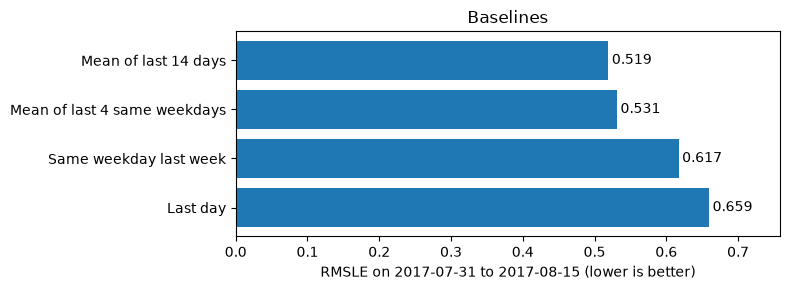

In [7]:
order = scores.drop("Zero").sort_values()

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(order.index[::-1], order.values[::-1])
for y, v in enumerate(order.values[::-1]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center")
ax.set_xlabel("RMSLE on 2017-07-31 to 2017-08-15 (lower is better)")
ax.set_title("Baselines")
ax.set_xlim(0, order.max() * 1.15)
fig.tight_layout()
fig.savefig(f"{IMAGES}/baselines.png", dpi=120)
plt.show()

**What we found:**
- **Zero** scores about 4.4, far worse than everything else. Good: the metric behaves as expected.
- **Averages beat single days.** "Mean of last 14 days" beats "last day", and "mean of last 4 same
  weekdays" beats "same weekday last week". A single day is noisy, especially for small series,
  and averaging several days cancels much of that noise.
- **Surprise: the plain 14-day mean wins here**, even though it ignores the weekly pattern that was
  so strong in notebook 01. Store 44's `GROCERY I` is a big, smooth series. Most of the 1,782 series
  are small and noisy, and for them averaging matters more than the weekday.
  The RMSLE gives small series a lot of weight, as section 3 showed.

## 5. A trap: the forecast that cheats

Here is a tempting rule: *"predict each day with the day before it"*. Code like `wide.shift(1)`
(move every value down one row) makes it a one-liner, and it scores well on many tutorials' charts.

In [8]:
# shift(1): each row gets the values of the previous row, i.e. "yesterday's sales".
cheat = wide.shift(1).iloc[-HORIZON:]
print(f"Yesterday's actual sales: RMSLE = {rmsle(actual, cheat):.4f}")

Yesterday's actual sales: RMSLE = 0.5461


**Why is this cheating?** To forecast 15 August this way, we need the sales of 14 August.
But we must make all 16 forecasts on 30 July, when 14 August is still in the future.
Only the forecast for the very first day (31 July) could honestly use "yesterday".

This is **leakage**, the most common bug in forecasting: the code runs, the score looks plausible,
and it can't be reproduced in real life. The Kaggle test has no sales at all, so this rule
can't even be computed there.

Two lessons:
1. **Always ask: on the day I make the forecast, would I know this value?** For a 16-day horizon,
   any feature must be at least 16 days old (this shapes the lag features in step 6).
2. Even with the leaked information, it scores *worse* than the honest 14-day mean.
   One noisy day is a weak predictor, however recent it is.

## 6. Does the error grow further into the future?

Intuitively, forecasting 1 day ahead should be easier than 16 days ahead. Let's score each forecast day separately.

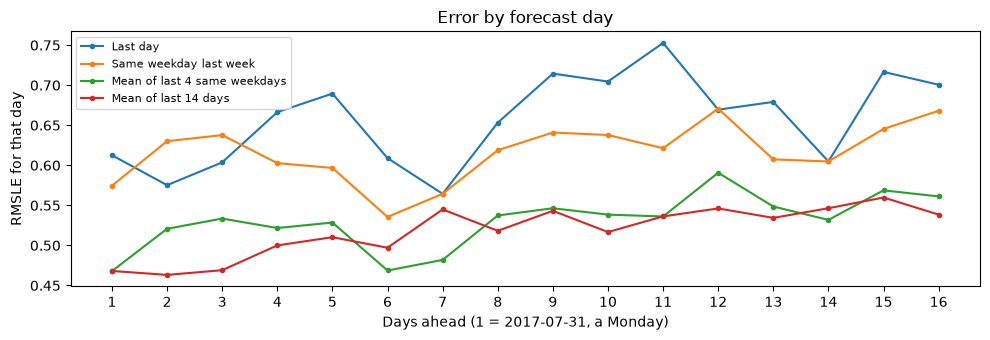

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for name in ["Last day", "Same weekday last week", "Mean of last 4 same weekdays", "Mean of last 14 days"]:
    per_day = [rmsle(actual.loc[d], forecasts[name].loc[d]) for d in actual.index]
    ax.plot(range(1, HORIZON + 1), per_day, marker="o", markersize=3, label=name)
ax.set_xlabel("Days ahead (1 = 2017-07-31, a Monday)")
ax.set_ylabel("RMSLE for that day")
ax.set_xticks(range(1, HORIZON + 1))
ax.set_title("Error by forecast day")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{IMAGES}/error_by_horizon.png", dpi=120)
plt.show()

**What we found:**
- **The error grows with the horizon.** The 14-day mean goes from about 0.47 on day 1 to about 0.55 in the
  second week; "last day" from about 0.6 to about 0.7. Forecasting further ahead is harder, as expected.
- **The ranking changes by weekday.** The weekday rule (green) beats the 14-day mean on days 6 and 7,
  **Saturday and Sunday**, but loses on most weekdays. That is the weekend effect from notebook 01:
  a flat average misses it, while a weekday average catches it but is noisier.
  This hints that **combining both ideas** (a smooth level from many days, plus a weekday adjustment)
  could beat each one alone. We try that in step 4.

This also matters later: a model's quality on day 1 tells us little about day 16, so we always score
the whole 16-day period, as Kaggle does.

## Summary

| Finding | Consequence |
|---|---|
| Best baseline: mean of last 14 days, **RMSLE ≈ 0.519** | The bar every model must clear |
| Averages beat single days | Noise is a bigger problem than missing patterns, especially in small series |
| `shift(1)` "yesterday" forecasts leak the future | Every feature must be ≥ 16 days old (step 6) |
| Errors grow slowly with the horizon | Always score all 16 days together |

**An open question for step 4.** All these scores come from **one** 16-day period.
Is the 14-day mean really the best rule, or did it just get lucky in these two weeks? Weekday rules might
win in another period. A single validation window is like judging a model on one fold.
In step 4 we repeat the test on several periods (*backtesting*) before trusting any ranking.